# 08 客觀成就：結婚、小孩、薪水、工時，怎麼變成滿意度與幸福？

計算機要讓使用者輸入「結婚沒、有幾個小孩、月薪多少、每週工作幾小時」，再換算成幸福。這需要兩段：
1. **第一段**：客觀條件 → 領域滿意度（工作、家庭、經濟）
2. **第二段**：領域滿意度 × 權重 → 幸福（notebook 03、04）

這本 notebook 估第一段，並深入看三個與題目最相關的客觀條件：**子女**、**收入**、**工時與職家衝突**。
參考文獻：收入與幸福呈對數關係（Killingsworth, Kahneman & Mellers, 2023）；有子女與幸福的關係依子女年齡與性別而異（Nelson, Kushlev & Lyubomirsky, 2014）；工作對家庭的衝突降低生活滿意（Allen et al., 2000）。

In [1]:
import numpy as np, pandas as pd
import statsmodels.formula.api as smf
from psfd_utils import *
plt = setup_plot()
main = pd.read_csv(DERIVED / "main_2020_2024.csv", low_memory=False)
main["age_c"] = (main.age - 45) / 10
main["hours_g"] = pd.cut(main.hours, [0, 39, 44, 49, 59, 200], labels=["<40", "40–44", "45–49", "50–59", "60+"])
main["kids_g"] = pd.cut(main.nkids, [-1, 0, 1, 2, 20], labels=["0", "1", "2", "3+"])
main["young_g"] = np.select([main.nkids == 0, main.youngest_child_age < 6, main.youngest_child_age < 18, main.youngest_child_age >= 18],
                            ["沒有子女", "最小 0–5 歲", "最小 6–17 歲", "子女皆成年"], default=None)
main["mar_g"] = main.marital.map({"married": "已婚", "never": "未婚", "divorced": "離婚/分居", "separated": "離婚/分居", "widowed": "喪偶"})


def fit(f, d):
    m0 = smf.ols(f, d).fit()
    return smf.ols(f, d).fit(cov_type="cluster", cov_kwds={"groups": d.loc[m0.model.data.row_labels, "pid"]})

## 1. 第一段模型：客觀條件 → 滿意度（2020–2024 合併）

In [2]:
emp = main[main.employed == 1].copy()
CT = "age_c + I(age_c**2) + female + health + edu_years + web + C(year)"
stage1 = {
    "工作滿意": fit(f"jobsat ~ log_income + C(hours_g) + {CT}", emp),
    "經濟滿意": fit(f"econsat ~ log_income + C(mar_g, Treatment('未婚')) + C(young_g, Treatment('沒有子女')) + {CT}", emp),
    "家庭滿意": fit(f"famsat ~ log_income + C(mar_g, Treatment('未婚')) + C(young_g, Treatment('沒有子女')) + C(kids_g) + C(hours_g) + {CT}", emp),
}
for k, m in stage1.items():
    print(f"\n==== {k}  N={int(m.nobs)}  R²={m.rsquared:.3f}")
    t = coef_table(m); print(t[~t.index.str.startswith("C(year)")].to_string())


==== 工作滿意  N=11601  R²=0.082
                       coef      se       p  ci_low  ci_high
Intercept            2.3297  0.0570  0.0000  2.2180   2.4414
C(hours_g)[T.40–44] -0.0192  0.0192  0.3176 -0.0568   0.0184
C(hours_g)[T.45–49] -0.0527  0.0216  0.0148 -0.0950  -0.0103
C(hours_g)[T.50–59] -0.0755  0.0231  0.0011 -0.1207  -0.0303
C(hours_g)[T.60+]   -0.0555  0.0256  0.0302 -0.1056  -0.0053
log_income           0.0669  0.0087  0.0000  0.0498   0.0840
age_c                0.0447  0.0081  0.0000  0.0289   0.0605
I(age_c ** 2)       -0.0026  0.0049  0.5970 -0.0121   0.0070
female               0.0173  0.0132  0.1902 -0.0086   0.0432
health               0.1703  0.0082  0.0000  0.1542   0.1865
edu_years           -0.0061  0.0030  0.0429 -0.0120  -0.0002
web                 -0.0833  0.0146  0.0000 -0.1120  -0.0546

==== 經濟滿意  N=11658  R²=0.109
                                              coef      se       p  ci_low  ci_high
Intercept                                   1.3775  0.0710  0.0

第一段的 R² 只有約 0.1–0.2：**客觀條件只解釋滿意度的一小部分**。同樣的月薪、同樣已婚有小孩，有人很滿意、有人不滿意。
這呼應 Diener 等人的經典發現：客觀生活條件對主觀幸福的解釋力有限，主觀評價才是關鍵（Diener, Suh, Lucas & Smith, 1999）。

## 2. 直接看幸福：客觀成就對幸福分數的總效果，與「經過」滿意度的部分

In [3]:
allr = main.dropna(subset=["swb", "health", "age"]).copy()
CTa = "age_c + I(age_c**2) + female + health + web + C(year)"
tot = fit(f"swb ~ C(mar_g, Treatment('未婚')) + C(young_g, Treatment('沒有子女')) + employed + {CTa}", allr)
med = fit(f"swb ~ C(mar_g, Treatment('未婚')) + C(young_g, Treatment('沒有子女')) + employed + famsat + econsat + {CTa}", allr)
keys = [k for k in tot.params.index if ("mar_g" in k or "young_g" in k or k == "employed")]
eff = pd.DataFrame({"總效果（幸福分數）": tot.params[keys], "p": tot.pvalues[keys],
                    "控制家庭與經濟滿意度後": med.params[keys]})
eff["經由滿意度的比例%"] = np.where(eff.p < 0.05, (1 - eff["控制家庭與經濟滿意度後"] / eff["總效果（幸福分數）"]) * 100, np.nan)  # 總效果不顯著時比例沒有意義
eff.round(2)

,總效果（幸福分數）,p,控制家庭與經濟滿意度後,經由滿意度的比例%
"C(mar_g, Treatment('未婚'))[T.喪偶]",-0.90,0.45,-2.18,NaN
"C(mar_g, Treatment('未婚'))[T.已婚]",3.54,0.00,1.38,60.84
"C(mar_g, Treatment('未婚'))[T.離婚/分居]",-1.21,0.18,-0.50,NaN
"C(young_g, Treatment('沒有子女'))[T.子女皆成年]",-0.05,0.95,0.17,NaN
"C(young_g, Treatment('沒有子女'))[T.最小 0–5 歲]",0.17,0.78,1.64,NaN
"C(young_g, Treatment('沒有子女'))[T.最小 6–17 歲]",0.02,0.98,0.79,NaN
employed,1.01,0.04,-0.07,106.43


In [4]:
# 只控制家庭滿意度（不含經濟滿意度）時，已婚優勢剩多少？
med_f = fit(f"swb ~ C(mar_g, Treatment('未婚')) + C(young_g, Treatment('沒有子女')) + employed + famsat + {CTa}", allr)
k = "C(mar_g, Treatment('未婚'))[T.已婚]"
print(f"已婚 vs 未婚：總效果 {tot.params[k]:.2f} 分")
print(f"  控制家庭滿意度後 {med_f.params[k]:.2f} 分（p = {med_f.pvalues[k]:.3f}）→ 經由家庭滿意度 {(1 - med_f.params[k] / tot.params[k]) * 100:.0f}%")
print(f"  再控制經濟滿意度後 {med.params[k]:.2f} 分（p = {med.pvalues[k]:.3f}）→ 經由兩者 {(1 - med.params[k] / tot.params[k]) * 100:.0f}%")

已婚 vs 未婚：總效果 3.54 分
  控制家庭滿意度後 1.52 分（p = 0.005）→ 經由家庭滿意度 57%
  再控制經濟滿意度後 1.38 分（p = 0.007）→ 經由兩者 61%


已婚者比未婚者幸福約 3.5 分，控制家庭滿意度後剩約 1.5 分（近六成經由家庭滿意度），再控制經濟滿意度後剩約 1.4 分——**婚姻的幸福優勢大部分是透過「家庭生活滿不滿意」而來**，但仍有一小段直接差距。
結婚本身不保證幸福：家庭生活很不滿意的已婚者，並不比單身的人快樂（下表第一列）。

In [5]:
q = allr.dropna(subset=["famsat", "mar_g"])
tab = q.pivot_table(index="famsat", columns="mar_g", values="swb", aggfunc="mean").round(1)
tab.index = tab.index.map({1: "很不滿意", 2: "不太滿意", 3: "還算滿意", 4: "很滿意"})
tab[["已婚", "未婚", "離婚/分居", "喪偶"]]

mar_g,已婚,未婚,離婚/分居,喪偶
famsat,,,,
很不滿意,31.6,34.0,29.6,31.2
不太滿意,49.1,47.7,45.5,40.5
還算滿意,65.7,62.8,62.6,65.0
很滿意,79.0,74.1,76.2,80.2


PosixPath('figures/fig08_marriage_famsat.png')

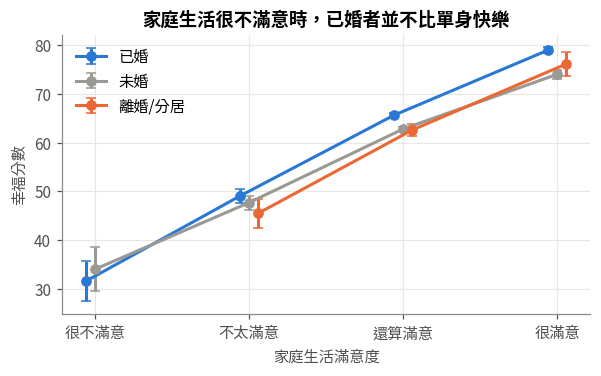

In [6]:
fig, ax = plt.subplots(figsize=(6.2, 3.3))
for mg, col in [("已婚", C_FAMILY), ("未婚", PALETTE["grey"]), ("離婚/分居", C_WORK)]:
    t = q[q.mar_g == mg].groupby("famsat").swb.agg(["mean", "count", "std"])
    t = t[t["count"] >= 30]
    ax.errorbar(t.index + {"已婚": -0.06, "未婚": 0, "離婚/分居": 0.06}[mg], t["mean"], yerr=1.96 * t["std"] / np.sqrt(t["count"]), marker="o", color=col, label=mg, capsize=3)
ax.set_xticks([1, 2, 3, 4], ["很不滿意", "不太滿意", "還算滿意", "很滿意"]); ax.set_xlabel("家庭生活滿意度"); ax.set_ylabel("幸福分數")
ax.legend(); ax.set_title("家庭生活很不滿意時，已婚者並不比單身快樂")
savefig(fig, "fig08_marriage_famsat")

## 3. 子女：有小孩比較幸福嗎？取決於孩子幾歲、你是爸爸還是媽媽

In [7]:
k = allr.dropna(subset=["young_g"]).copy()
mk = fit(f"swb ~ C(young_g, Treatment('沒有子女')) * female + C(mar_g, Treatment('未婚')) + {CTa}", k)
t = coef_table(mk); t[t.index.str.contains("young_g")]

,coef,se,p,ci_low,ci_high
"C(young_g, Treatment('沒有子女'))[T.子女皆成年]",0.1818,1.0260,0.8593,-1.8291,2.1928
"C(young_g, Treatment('沒有子女'))[T.最小 0–5 歲]",0.2184,0.7413,0.7682,-1.2345,1.6714
"C(young_g, Treatment('沒有子女'))[T.最小 6–17 歲]",0.4146,0.7747,0.5926,-1.1039,1.9330
"C(young_g, Treatment('沒有子女'))[T.子女皆成年]:female",-0.5011,0.9227,0.5871,-2.3096,1.3074
"C(young_g, Treatment('沒有子女'))[T.最小 0–5 歲]:female",-0.2209,0.8466,0.7942,-1.8801,1.4384
"C(young_g, Treatment('沒有子女'))[T.最小 6–17 歲]:female",-0.8033,0.8607,0.3507,-2.4903,0.8837


In [8]:
rows = []
CTs = "age_c + I(age_c**2) + health + web + C(year)"      # 分性別估計時不能再放性別
for sex, g in k.groupby("female"):
    m = fit(f"swb ~ C(young_g, Treatment('沒有子女')) + C(mar_g, Treatment('未婚')) + {CTs}", g)
    for lv in ["最小 0–5 歲", "最小 6–17 歲", "子女皆成年"]:
        key = f"C(young_g, Treatment('沒有子女'))[T.{lv}]"
        rows.append(dict(性別="母親" if sex == 1 else "父親", 子女階段=lv, 差異=m.params[key], lo=m.conf_int().loc[key, 0], hi=m.conf_int().loc[key, 1]))
kid_tab = pd.DataFrame(rows)
kid_tab.round(2)

,性別,子女階段,差異,lo,hi
0,父親,最小 0–5 歲,0.18,-1.52,1.89
1,父親,最小 6–17 歲,0.61,-1.17,2.40
2,父親,子女皆成年,1.24,-1.25,3.74
3,母親,最小 0–5 歲,-0.02,-1.76,1.73
4,母親,最小 6–17 歲,-0.61,-2.45,1.23
5,母親,子女皆成年,-1.37,-3.84,1.10


PosixPath('figures/fig08b_children.png')

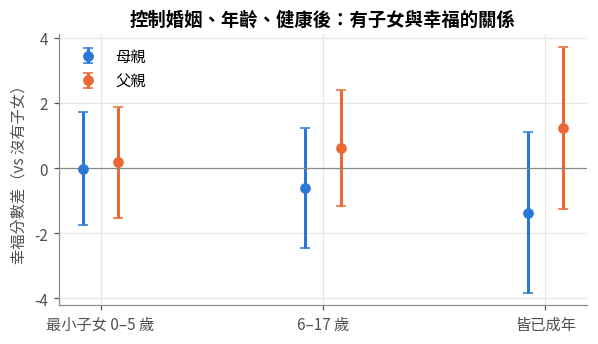

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
for sx, col, off in [("母親", C_FAMILY, -0.08), ("父親", C_WORK, 0.08)]:
    t = kid_tab[kid_tab.性別 == sx]
    x = np.arange(len(t)) + off
    ax.errorbar(x, t.差異, yerr=[t.差異 - t.lo, t.hi - t.差異], fmt="o", color=col, label=sx, capsize=3)
ax.axhline(0, color="#8a8984", lw=0.8)
ax.set_xticks(range(3), ["最小子女 0–5 歲", "6–17 歲", "皆已成年"]); ax.set_ylabel("幸福分數差（vs 沒有子女）")
ax.legend(); ax.set_title("控制婚姻、年齡、健康後：有子女與幸福的關係")
savefig(fig, "fig08b_children")

## 4. 收入：越多越好？有沒有「夠了」的點？

In [10]:
e = emp.dropna(subset=["income", "swb"]).copy()
e["inc_dec"] = e.groupby("year").income.transform(lambda s: pd.qcut(s, 10, labels=False, duplicates="drop") + 1)
t = e.groupby("inc_dec").agg(年收入中位數萬=("income", lambda s: s.median() / 1e4), 幸福=("swb", "mean"), 工作滿意=("jobsat", "mean"), 經濟滿意=("econsat", "mean"), N=("swb", "size")).round(2)
t

,年收入中位數萬,幸福,工作滿意,經濟滿意,N
inc_dec,,,,,
1,10.00,63.15,2.95,2.44,1238
2,32.45,63.64,2.97,2.46,1470
3,40.00,63.11,2.96,2.47,940
4,48.00,65.30,2.96,2.50,1408
5,54.00,65.34,2.98,2.52,1153
6,60.00,66.23,3.01,2.61,1244
7,70.00,66.64,3.00,2.64,1145
8,85.00,68.09,3.06,2.73,1192
9,100.00,69.41,3.12,2.80,1164


log 收入：每增加 1 單位 log(1+萬元) 幸福 +2.35 分，R²=0.1820
收入加倍 ≈ 幸福 +1.63 分


PosixPath('figures/fig08c_income.png')

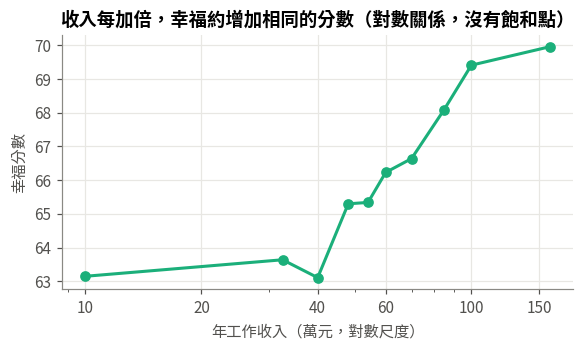

In [11]:
ml = fit(f"swb ~ log_income + {CTa}", e)
mlin = fit(f"swb ~ I(income/1e5) + I((income/1e5)**2) + {CTa}", e)
print("log 收入：每增加 1 單位 log(1+萬元) 幸福 +%.2f 分，R²=%.4f" % (ml.params["log_income"], ml.rsquared))
print("收入加倍 ≈ 幸福 +%.2f 分" % (ml.params["log_income"] * np.log(2)))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t.年收入中位數萬, t.幸福, marker="o", color=C_ECON)
ax.set_xscale("log"); ax.set_xlabel("年工作收入（萬元，對數尺度）"); ax.set_ylabel("幸福分數")
ax.set_xticks([10, 20, 40, 60, 100, 150], ["10", "20", "40", "60", "100", "150"])
ax.set_title("收入每加倍，幸福約增加相同的分數（對數關係，沒有飽和點）")
savefig(fig, "fig08c_income")

## 5. 工時與職家衝突

In [12]:
t = emp.groupby("hours_g", observed=True).agg(幸福=("swb", "mean"), 工作滿意=("jobsat", "mean"), 家庭滿意=("famsat", "mean"), N=("swb", "size")).round(2)
t

,幸福,工作滿意,家庭滿意,N
hours_g,,,,
<40,66.60,3.01,3.15,1874
40–44,66.72,3.02,3.15,5919
45–49,65.66,2.98,3.12,2215
50–59,64.71,2.97,3.14,1732
60+,63.42,3.00,3.12,1453


In [13]:
wf = emp.dropna(subset=["wfc", "swb"]).copy()
wf["wfc_z"] = wf.groupby("year").wfc.transform(z)
for c in ["swb", "jobsat", "famsat", "econsat", "health"]: wf[c + "_z"] = wf.groupby("year")[c].transform(z)
m_w = fit("swb_z ~ jobsat_z + famsat_z + econsat_z + health_z + wfc_z + age_c + female + web + C(year)", wf)
print("N =", int(m_w.nobs), "（2020 與 2024 有職家衝突題）")
coef_table(m_w, ["jobsat_z", "famsat_z", "wfc_z"])

N = 8057 （2020 與 2024 有職家衝突題）


,coef,se,p,ci_low,ci_high
jobsat_z,0.1818,0.0112,0.0,0.1598,0.2039
famsat_z,0.2609,0.0112,0.0,0.2389,0.2829
wfc_z,-0.1834,0.0103,0.0,-0.2036,-0.1633


In [14]:
m_w2 = fit("swb_z ~ jobsat_z + famsat_z + econsat_z + health_z + wfc_z * has_kids + age_c + female + web + C(year)", wf)
coef_table(m_w2, ["wfc_z", "has_kids", "wfc_z:has_kids"])

,coef,se,p,ci_low,ci_high
wfc_z,-0.1914,0.0145,0.000,-0.2198,-0.1631
has_kids,0.1406,0.0210,0.000,0.0994,0.1817
wfc_z:has_kids,-0.0024,0.0193,0.899,-0.0403,0.0354


## 6. 2020 的工作特性 13 題：哪種工作讓人滿意？

In [15]:
JC = {"jobchar_00": "受人尊重", "jobchar_01": "重複單調", "jobchar_02": "耗費體力", "jobchar_03": "高度危險", "jobchar_04": "收入高",
      "jobchar_05": "有升遷機會", "jobchar_06": "有趣", "jobchar_07": "可單獨作業", "jobchar_08": "有保障", "jobchar_09": "可以幫助別人",
      "jobchar_10": "對社會有用", "jobchar_11": "能和人接觸", "jobchar_12": "能發揮所學"}
j = emp[emp.year == 2020].dropna(subset=list(JC) + ["jobsat"]).copy()
for c in list(JC) + ["jobsat"]: j[c] = z(j[c])
mj = smf.ols("jobsat ~ " + " + ".join(JC) + " + age_c + female + log_income", j).fit(cov_type="HC1")
jt = coef_table(mj, list(JC)).rename(index=JC).sort_values("coef", ascending=False)
print("N =", int(mj.nobs), " R² =", round(mj.rsquared, 3))
jt

N = 3737  R² = 0.233


,coef,se,p,ci_low,ci_high
有趣,0.2672,0.0180,0.0000,0.2318,0.3025
有保障,0.1571,0.0178,0.0000,0.1222,0.1920
收入高,0.1566,0.0180,0.0000,0.1213,0.1919
受人尊重,0.1355,0.0180,0.0000,0.1003,0.1708
對社會有用,0.0438,0.0186,0.0183,0.0074,0.0802
重複單調,0.0262,0.0157,0.0940,-0.0045,0.0570
高度危險,-0.0050,0.0185,0.7882,-0.0412,0.0313
可以幫助別人,-0.0069,0.0190,0.7179,-0.0440,0.0303
可單獨作業,-0.0129,0.0154,0.3999,-0.0430,0.0172
能發揮所學,-0.0217,0.0164,0.1845,-0.0538,0.0104


In [16]:
for nm, m in stage1.items():
    pd.DataFrame({"coef": m.params, "se": m.bse}).to_csv(DERIVED / f"stage1_{nm}.csv")
kid_tab.to_csv(DERIVED / "children_effects.csv", index=False)
eff.to_csv(DERIVED / "objective_total_effects.csv")
jt.to_csv(DERIVED / "job_characteristics_2020.csv")